# 3 · Etiket analizi (Kriter 3 ve 4)

**Sorular:** Etiket nereden geliyor? Sınıflar nasıl dağılmış? Etiketler tutarlı mı, hatalı olabilecek yerler var mı?
Neden 0 / 1 / 2+ diye üç sınıf seçtik?

**Etiketin kökeni:** Ev sakinlerinin telefon konum bildirimleri (geo-fence) ve kâğıda yazdıkları giriş-çıkış kayıtları.
Makaleye göre yazarlar yalnız **dolu/boş** bilgisini doğrulamış; **kişi sayısı doğrulanmamış** ve misafirler dahil.

**Kurulum hücresi.** Önce bunu çalıştır (ya da Run → Run All). Kütüphaneleri, projenin `src/` kodlarını ve
etiketleri yükler; sonraki hücreler buradaki isimleri kullanır.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))           # projenin kendi kodları (src/) buradan çağrılır
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from build import OUT, INTERIM, ENV_COLS, HOMES, hubs_of
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLS = ["0 kişi", "1 kişi", "2+ kişi"]; RENK = ["#2A78D6", "#EB6834", "#1BAF7A"]   # bütün grafiklerde aynı renkler
LAB = {h: pd.read_parquet(OUT / h / "labels.parquet") for h in HOMES}           # etiketler (her ev için 10 sn ızgara)
print("evler:", HOMES, "| toplam pencere:", sum(map(len, LAB.values())))

evler: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'] | toplam pencere: 1311925


## 3.1 Kişi sayısı (0–5) ev ev

In [2]:
num = pd.concat({h: LAB[h]["number"].value_counts().sort_index() for h in HOMES}, axis=1).fillna(0).astype(int).T
num.loc["Toplam"] = num.sum(); num

number,0,1,2,3,4,5
H1,45921,58866,76696,51980,24382,0
H2,58150,88189,541,0,0,0
H3,65800,55632,42945,72369,23128,42526
H4,26928,72499,36715,10738,0,0
H5,31606,49124,48870,0,0,0
H6,174562,153758,0,0,0,0
Toplam,402967,478068,205767,135087,47510,42526


In [3]:
sakin = {"H1": 4, "H2": 1, "H3": 4, "H4": 3, "H5": 2, "H6": 1}   # Home_overview.csv'den (Notebook 1)
for h in HOMES:
    fazla = LAB[h][LAB[h]["number"] > sakin[h]]
    if len(fazla):
        print(f"{h}: {sakin[h]} kişi yaşıyor ama {len(fazla):,} pencerede {sorted(fazla['number'].unique())} kişi yazıyor "
              f"({fazla['ts'].min():%d.%m} – {fazla['ts'].max():%d.%m})")

H2: 1 kişi yaşıyor ama 541 pencerede [np.int64(2)] kişi yazıyor (26.03 – 26.03)
H3: 4 kişi yaşıyor ama 42,526 pencerede [np.int64(5)] kişi yazıyor (23.07 – 04.08)


**Etiket tutarsızlığı bulundu:** kişi sayısı, evde yaşayan sayısını aşıyor. Neden: giriş-çıkış kaydı misafirleri de
sayıyor (H3'te iki haftalık bir misafir, H2'de 1,5 saatlik). Hatalı değil ama "evde yaşayan" değil "evde bulunan" sayısı.

## 3.2 Tutarlılık: `occupied` ile `number` uyuşuyor mu?

Mantıken `occupied = 1` ⇔ `number > 0` olmalı.

In [4]:
for h in HOMES:
    g = LAB[h]; bad = ((g["occupied"] == 1) != (g["number"] > 0)).sum()
    print(f"{h}: uyuşmayan satır {bad}")

H1: uyuşmayan satır 0
H2: uyuşmayan satır 0
H3: uyuşmayan satır 0
H4: uyuşmayan satır 0
H5: uyuşmayan satır 0
H6: uyuşmayan satır 0


## 3.3 Üç sınıfa indirme: 0 / 1 / 2+

`build_labels`: `cls = number.clip(upper=2)` → 2 ve üzeri tek sınıf.

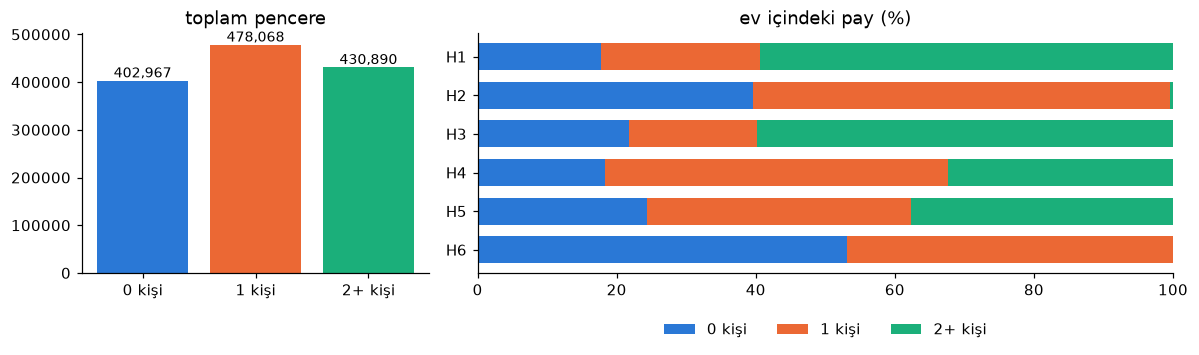

toplam pay (%): [30.7, 36.4, 32.8] | yönerge: ≥3 sınıf, ≥150/sınıf, ≥500 toplam ✓


In [5]:
cls = pd.concat({h: LAB[h]["cls"].value_counts(normalize=True).sort_index() * 100 for h in HOMES}, axis=1).T.fillna(0)
cls.columns = CLS
tot = pd.concat(LAB.values())["cls"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(CLS, tot.values, color=RENK); ax[0].set_title("toplam pencere")
for k, v in enumerate(tot.values): ax[0].text(k, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
cls[::-1].plot.barh(stacked=True, color=RENK, ax=ax[1], width=0.7, legend=False); ax[1].set_title("ev içindeki pay (%)")
ax[1].legend(CLS, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False); plt.tight_layout(); plt.show()
print("toplam pay (%):", (tot / tot.sum() * 100).round(1).tolist(), "| yönerge: ≥3 sınıf, ≥150/sınıf, ≥500 toplam ✓")

**Gözlem:** Toplamda sınıflar dengeli (%31 / %36 / %33). Ev bazında değil: H2 ve H6'da 2+ yok, H1 ve H3'te 2+ baskın.
**Modele etkisi:** Test evi H2 ya da H6 olduğunda 2+ ölçülemez; bölme planında sınıf bazında raporlama (Notebook 8).

## 3.4 Neden 2'den sonrasını ayırmadık? (kameraya göre)

Zone etiketi: yazarların insan algılayıcısı seçilen karede insan gördü mü (1/0). Kişi sayısına göre "en az bir kamerada
insan görülme oranı"na bakıyoruz. Sensör 2, 3, 4 kişiyi ayırt edebiliyorsa bu oran kişi sayısıyla artmalı.

In [6]:
rows = []
for h in HOMES:
    z = np.stack([pd.read_parquet(OUT / h / f"{hub}_img.parquet")["zone"].to_numpy() for hub in hubs_of(h)])
    seen = (z == 1).any(0); has = (z >= 0).any(0)                       # en az bir kamerada insan / değerlendirilebilir kare
    g = LAB[h]; night = g["ts"].dt.hour < 6
    rows.append(pd.DataFrame({"kişi": g["number"].clip(upper=4), "gece": night, "görüldü": seen, "kare": has}))
D = pd.concat(rows); D = D[D["kare"]]
t = D.groupby(["kişi", "gece"])["görüldü"].mean().unstack() * 100
t.columns = ["gündüz %", "gece %"]; t.index = ["0", "1", "2", "3", "4+"]; t.round(1)

,gündüz %,gece %
0,1.3,0.0
1,14.7,13.2
2,32.3,0.7
3,32.1,2.6
4+,33.7,1.3


**Okuma:** Gündüz 1 kişiden 2 kişiye görülme oranı ~iki katına çıkıyor, ama 2, 3 ve 4+ kişide aynı (~%32–34). Yani
sensörler 2'den sonrasını ayırt etmiyor; üstelik kişi sayısı doğrulanmamış ve misafir içeriyor. Bu yüzden 2 ve üzeri tek sınıf.
(Gece kareler çoğunlukla karanlık; oranlar düşük.)

## 3.5 Etiket gürültüsü: etiket "kimse yok" derken kamera insan görüyor mu?

Payda: etiketi 0 olan ve en az bir kamerada değerlendirilebilir karesi olan pencereler (karanlıkta kamera zaten göremez).

In [7]:
for h in HOMES:
    z = np.stack([pd.read_parquet(OUT / h / f"{hub}_img.parquet")["zone"].to_numpy() for hub in hubs_of(h)])
    bos = LAB[h]["cls"].to_numpy() == 0; seen = (z == 1).any(0); kare = (z >= 0).any(0)   # kare = değerlendirilebilir kare var
    print(f"{h}: etiket 0 kişi iken kamerada insan: {(bos & seen).sum():,} pencere "
          f"(karesi olan boş pencerelerin %{100 * (bos & seen).sum() / (bos & kare).sum():.1f}'i)")

H1: etiket 0 kişi iken kamerada insan: 1,793 pencere (karesi olan boş pencerelerin %3.9'i)
H2: etiket 0 kişi iken kamerada insan: 19 pencere (karesi olan boş pencerelerin %0.0'i)
H3: etiket 0 kişi iken kamerada insan: 1,537 pencere (karesi olan boş pencerelerin %2.7'i)
H4: etiket 0 kişi iken kamerada insan: 105 pencere (karesi olan boş pencerelerin %0.5'i)
H5: etiket 0 kişi iken kamerada insan: 245 pencere (karesi olan boş pencerelerin %1.0'i)
H6: etiket 0 kişi iken kamerada insan: 154 pencere (karesi olan boş pencerelerin %0.1'i)


En kötü evde ~%4. Etiketler çoğunlukla tutarlı ama kusursuz değil. Bir kısmı algılayıcının yanlış alarmı da olabilir
(örnek karelerin çoğu karanlık). Kısıt olarak raporlandı.

## 3.6 Etiket zamanla ne kadar değişiyor? (bölme için kritik)

In [8]:
ayni = np.mean(np.concatenate([(g["cls"].to_numpy()[1:] == g["cls"].to_numpy()[:-1]) for g in LAB.values()]))
print(f"ardışık iki pencerenin etiketi aynı: %{100 * ayni:.3f}  (10.000 geçişte ~{10000 * (1 - ayni):.0f} değişim)")
seg = []
for h, g in LAB.items():
    c = g["cls"].to_numpy(); t = g["ts"]
    brk = np.r_[0, np.flatnonzero((c[1:] != c[:-1]) | (t.diff().dt.total_seconds().to_numpy()[1:] != 10)) + 1, len(c)]
    seg += [(c[a], (b - a) * 10 / 60) for a, b in zip(brk[:-1], brk[1:])]
seg = pd.DataFrame(seg, columns=["sınıf", "dakika"])
seg.groupby("sınıf")["dakika"].median().rename(index=dict(enumerate(CLS))).round(0).rename("ortanca segment (dk)")

ardışık iki pencerenin etiketi aynı: %99.947  (10.000 geçişte ~5 değişim)


sınıf
0 kişi     143.0
1 kişi      74.0
2+ kişi    364.0
Name: ortanca segment (dk), dtype: float64

**Önemi:** Bir durum ortalama saatlerce sürüyor (2+ için ~6 saat). Yan yana iki pencere neredeyse aynı örnek; rastgele
bölmede biri eğitimde biri testte olursa model ezberler. Bölme ve 6 saatlik boşluk kararı buradan (Notebook 8).

## 3.7 Sınıf günün saatine bağlı mı?

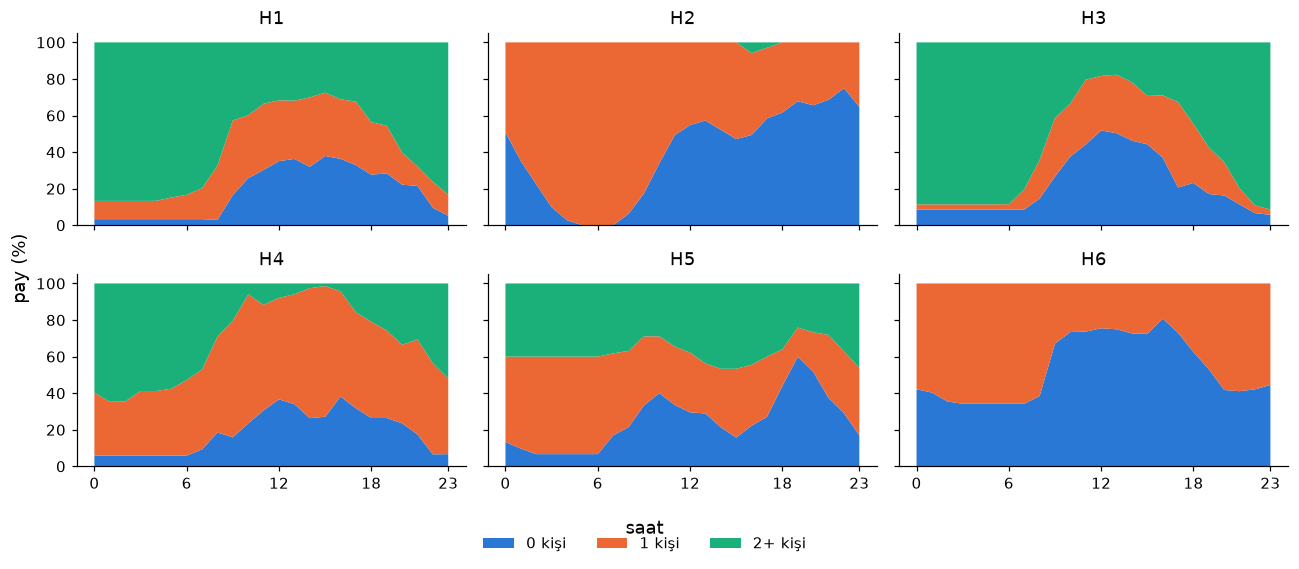

H1: 2+ payı gece 00–05 %86.4 | öğlen 11–16 %31.0
H3: 2+ payı gece 00–05 %88.6 | öğlen 11–16 %22.7
H4: 2+ payı gece 00–05 %60.7 | öğlen 11–16 %5.6


In [9]:
fig, ax = plt.subplots(2, 3, figsize=(12, 5), sharex=True, sharey=True)
for a, h in zip(ax.ravel(), HOMES):
    g = LAB[h]; p = pd.crosstab(g["ts"].dt.hour, g["cls"], normalize="index").reindex(columns=[0, 1, 2], fill_value=0) * 100
    a.stackplot(p.index, p.T.values, colors=RENK); a.set_title(h); a.set_xticks([0, 6, 12, 18, 23])
fig.supxlabel("saat"); fig.supylabel("pay (%)"); fig.legend(CLS, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.04), frameon=False)
plt.tight_layout(); plt.show()
for h in ["H1", "H3", "H4"]:
    g = LAB[h]; hr = g["ts"].dt.hour
    print(f"{h}: 2+ payı gece 00–05 %{100*(g.loc[hr<6,'cls']==2).mean():.1f} | öğlen 11–16 %{100*(g.loc[hr.between(11,16),'cls']==2).mean():.1f}")

**Yanlılık (bias):** Çok kişilik evlerde gece neredeyse hep 2+. Model insanı değil saati öğrenebilir. **Modele etkisi:**
saat bilgisi modele açık girdi olarak verilmeyecek; final hata analizinde gece ve gündüz ayrı raporlanacak.